In [16]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

In [17]:
Kandi=pd.read_csv("data\KANDI.csv")

Parakou=pd.read_csv("data\PARAKOU.csv")

<>:1: SyntaxWarning: invalid escape sequence '\K'
<>:3: SyntaxWarning: invalid escape sequence '\P'
<>:1: SyntaxWarning: invalid escape sequence '\K'
<>:3: SyntaxWarning: invalid escape sequence '\P'
C:\Users\HP CORE I5\AppData\Local\Temp\ipykernel_3840\1958332346.py:1: SyntaxWarning: invalid escape sequence '\K'
  Kandi=pd.read_csv("data\KANDI.csv")
C:\Users\HP CORE I5\AppData\Local\Temp\ipykernel_3840\1958332346.py:3: SyntaxWarning: invalid escape sequence '\P'
  Parakou=pd.read_csv("data\PARAKOU.csv")


In [18]:
Kandi.head()

,Lieu,annee,mois,jour,Pression,Temperature_Max,Temperature_Min,Humidite,Vitesse_Vent,Pluviometrie
0,KANDI_AEROPORT,2015,1,1,979.9,32.0,13.4,32.0,2.4,0.0
1,KANDI_AEROPORT,2015,1,2,981.4,30.3,17.4,26.0,2.3,0.0
2,KANDI_AEROPORT,2015,1,3,982.8,29.2,17.7,20.0,3.5,0.0
3,KANDI_AEROPORT,2015,1,4,983.8,29.0,15.8,20.0,2.8,0.0
4,KANDI_AEROPORT,2015,1,5,982.7,29.5,13.5,29.0,3.0,0.0


In [19]:
Parakou.head()

,Lieu,annee,mois,jour,Pression,Temperature_Max,Temperature_Min,Humidite,Vitesse_Vent,Pluviometrie
0,PARAKOU_AEROPORT,2015,1,1,967.5,34.6,19.2,23.0,3.6,0.0
1,PARAKOU_AEROPORT,2015,1,2,968.6,32.6,18.5,24.0,4.3,0.0
2,PARAKOU_AEROPORT,2015,1,3,969.9,32.5,18.9,20.0,4.9,0.0
3,PARAKOU_AEROPORT,2015,1,4,970.8,32.5,16.5,23.0,5.0,0.0
4,PARAKOU_AEROPORT,2015,1,5,969.9,31.9,15.9,23.0,5.1,0.0


In [20]:
Kandi.isnull().sum()[0<Kandi.isnull().sum()]

Pression        66
Humidite         5
Vitesse_Vent    31
Pluviometrie     1
dtype: int64

In [21]:
Parakou.isnull().sum()[0<Parakou.isnull().sum()]

Pression           72
Temperature_Max    25
Temperature_Min     4
Humidite           36
Vitesse_Vent        4
dtype: int64

In [22]:
Kandi=Kandi.drop([Kandi[Kandi.Pluviometrie.isnull()].index[0]],axis=0)

Kandi[Kandi.Pluviometrie.isnull()]

,Lieu,annee,mois,jour,Pression,Temperature_Max,Temperature_Min,Humidite,Vitesse_Vent,Pluviometrie


In [23]:
import missingno as msn

<Axes: >

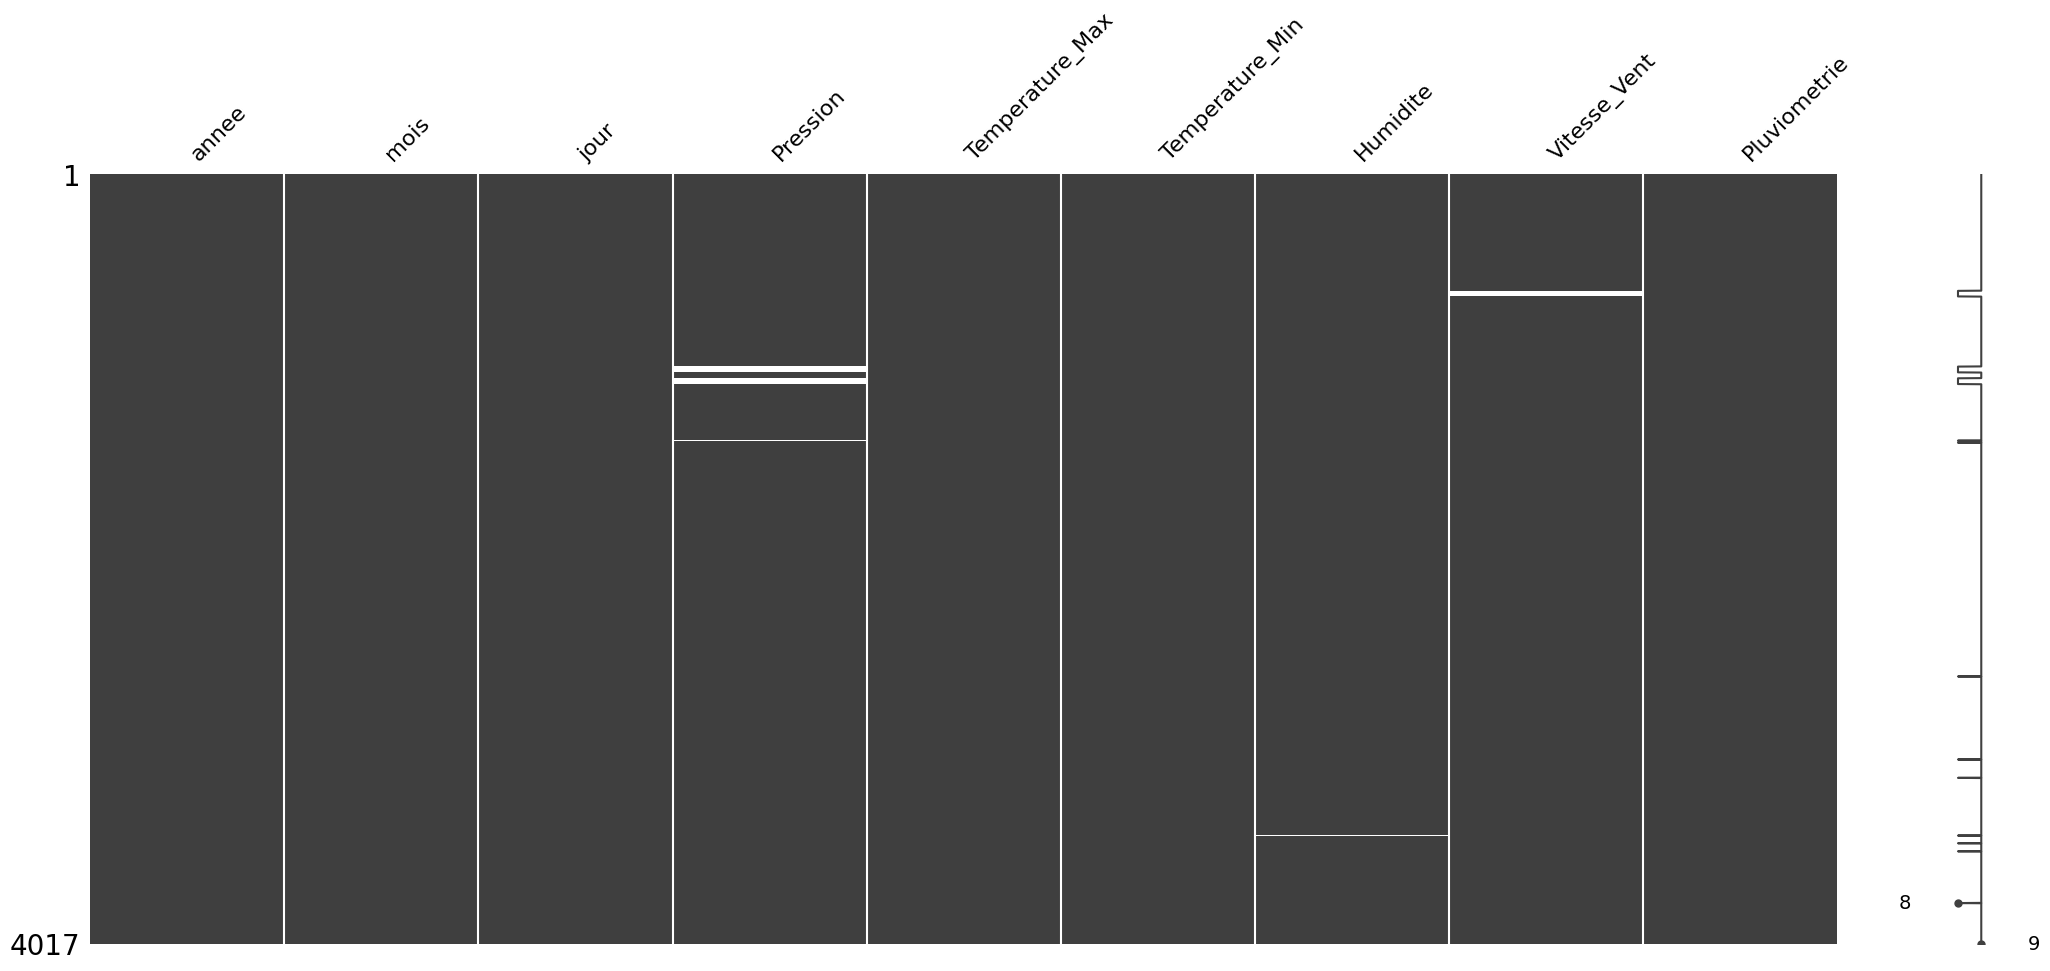

In [24]:
msn.matrix(Kandi.select_dtypes(include="number"))

<Axes: >

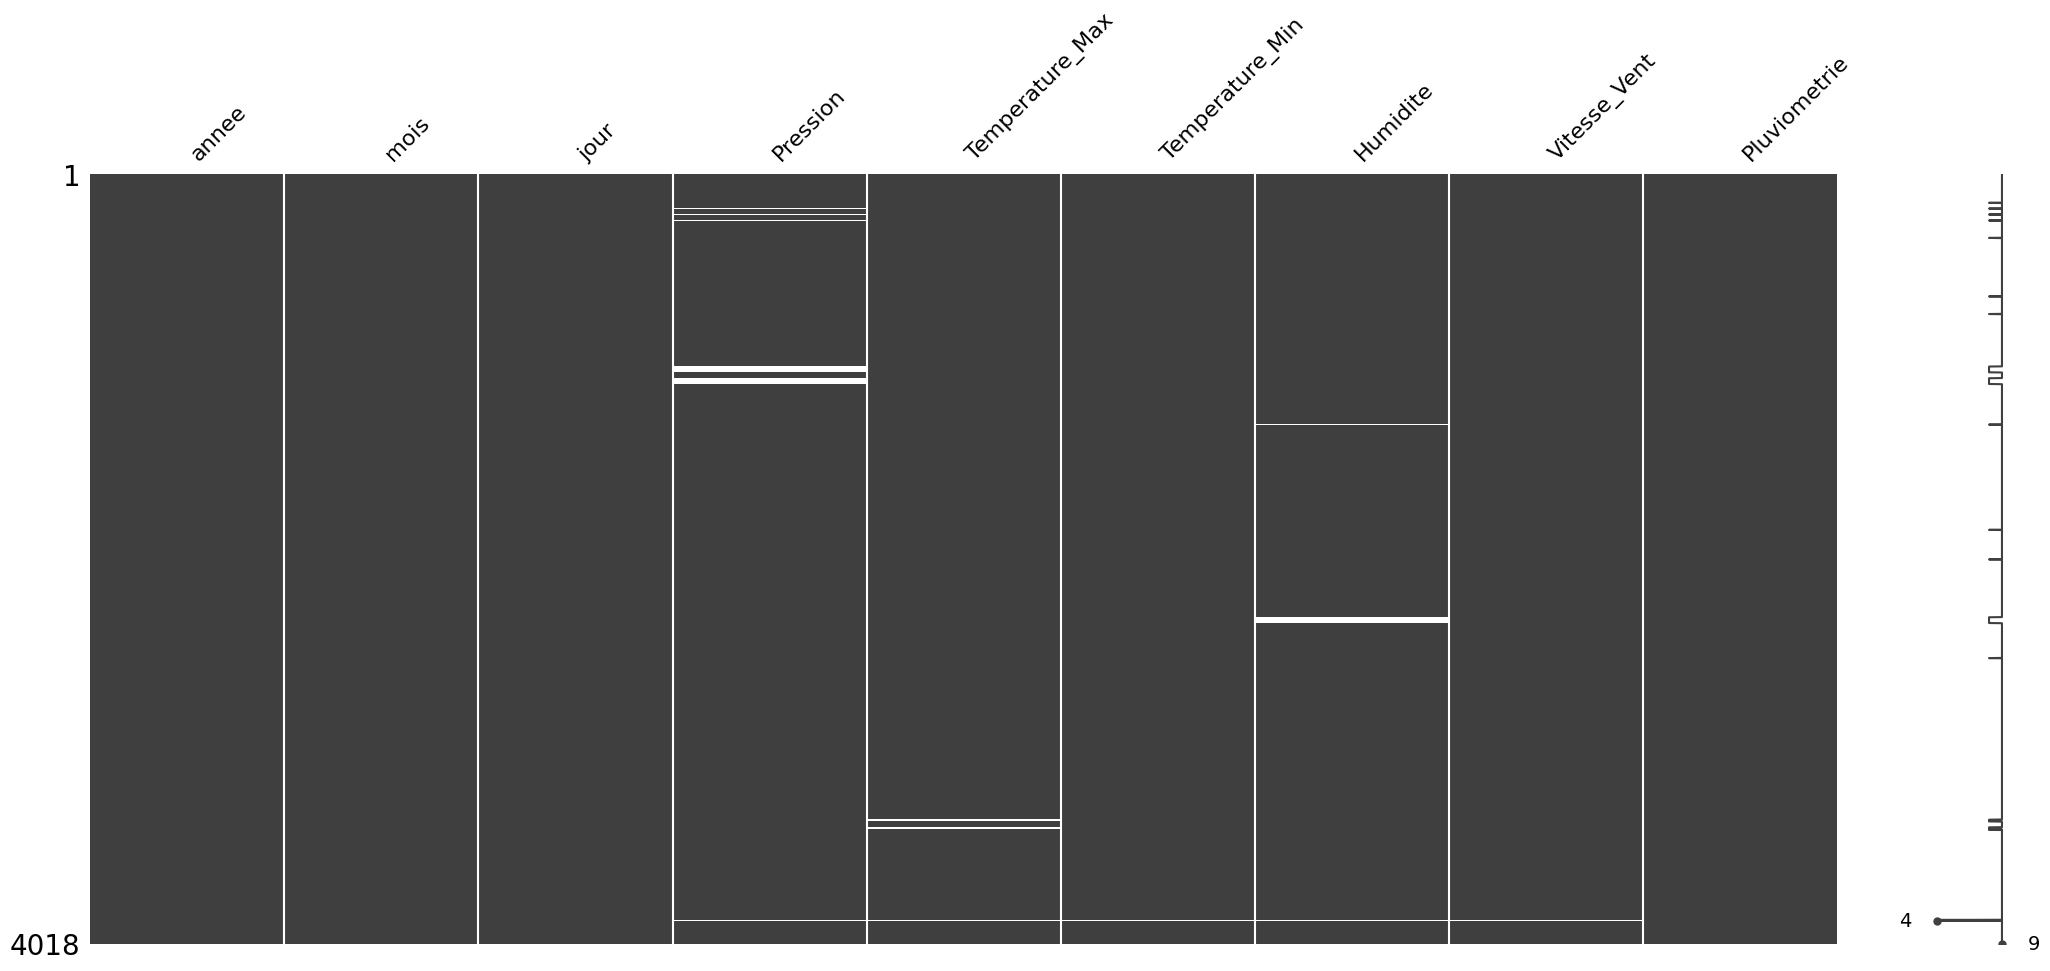

In [25]:
msn.matrix(Parakou.select_dtypes(include="number"))

In [26]:
Parakou=Parakou.dropna(thresh=6)

<Axes: >

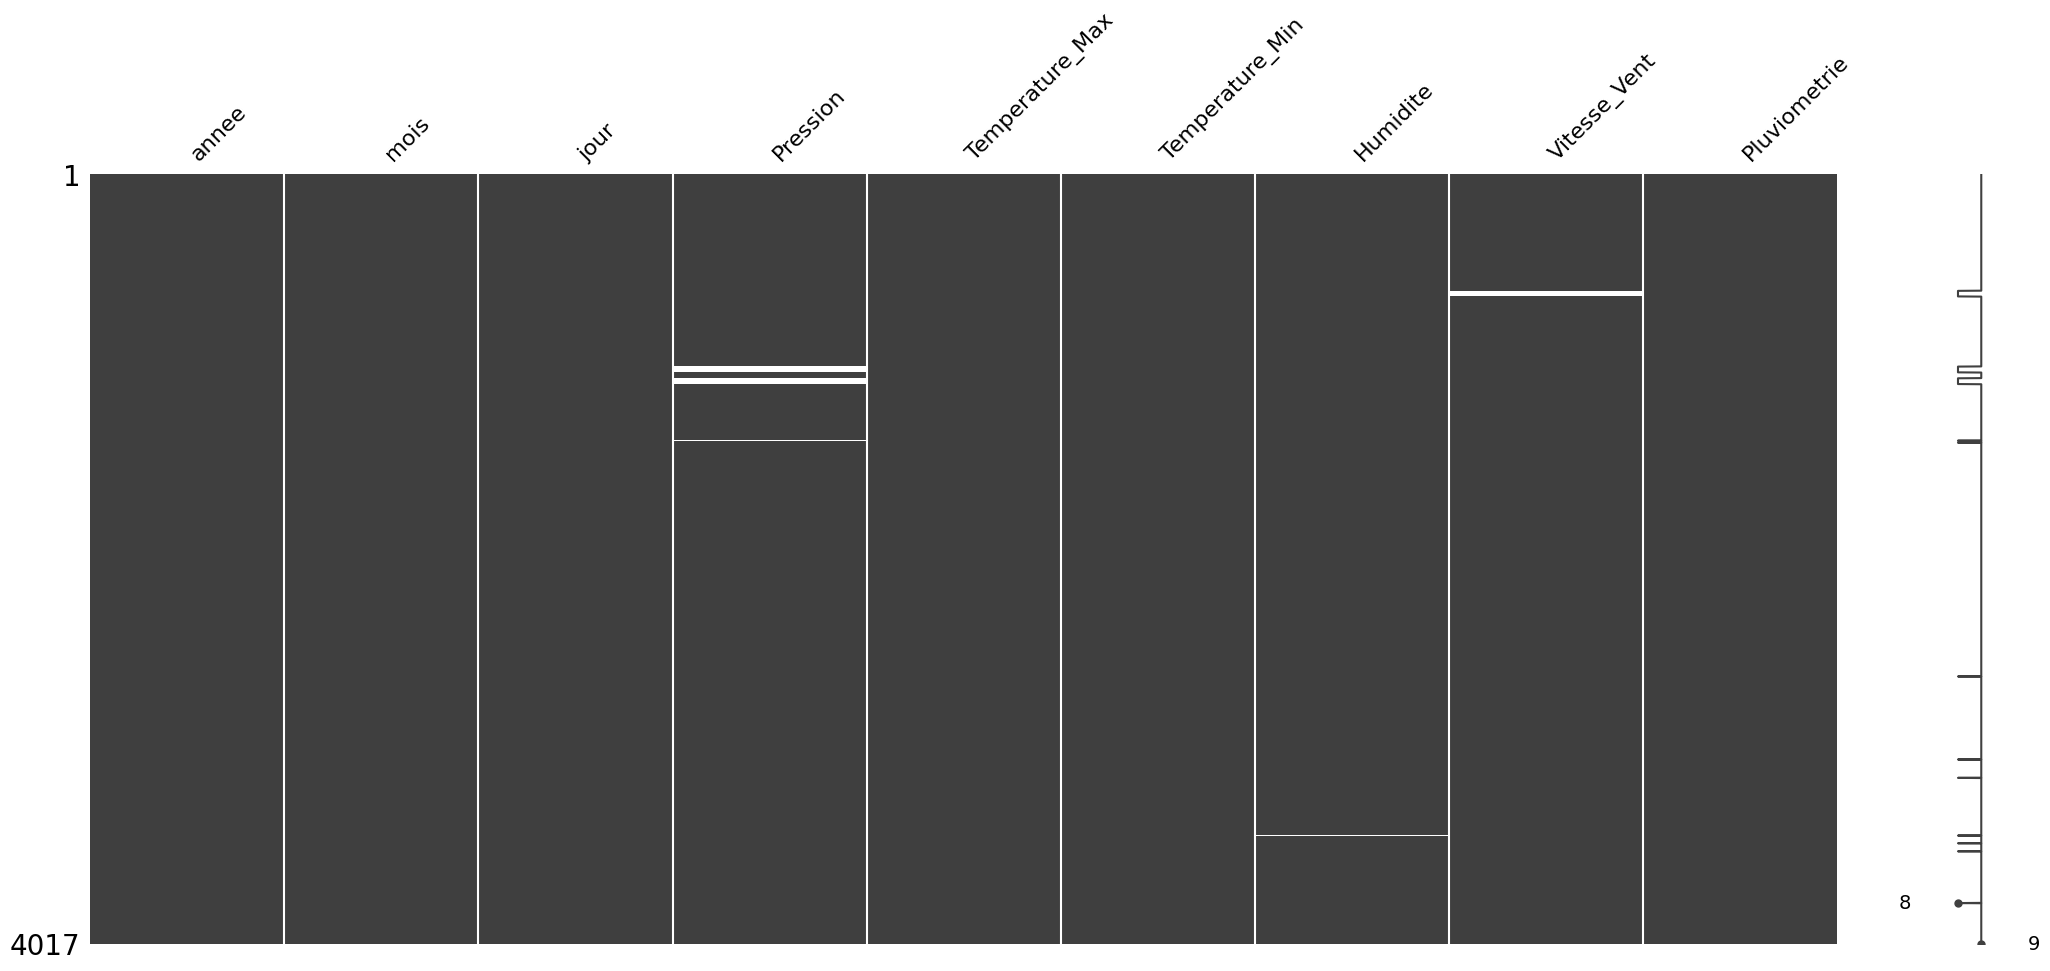

In [27]:
msn.matrix(Kandi.select_dtypes(include="number"))

<Axes: >

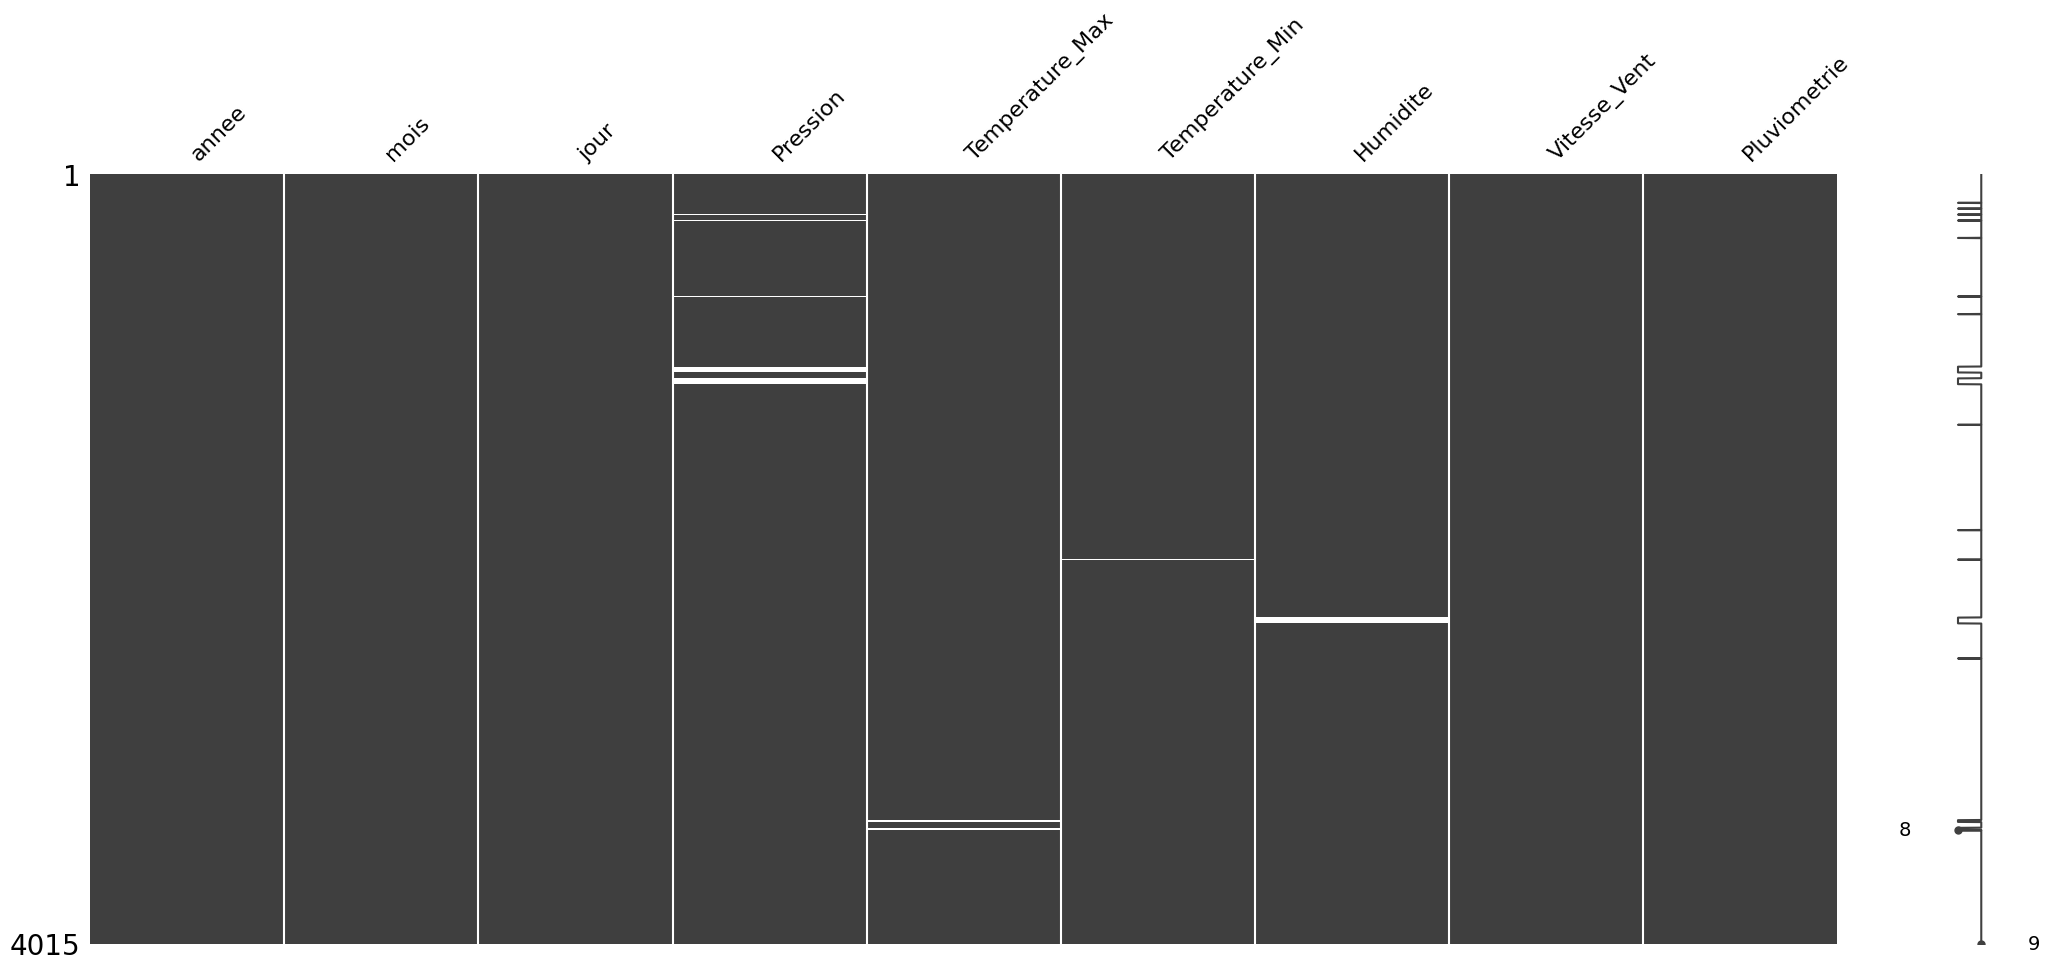

In [28]:
msn.matrix(Parakou.select_dtypes(include="number"))

In [29]:
from sklearn.metrics import mean_absolute_error,mean_squared_error

In [30]:
"""def methode_impute_moy(data_inpute,liste_variable_marquante):
    donnee=data_inpute.copy()
    for variable in liste_variable_marquante:
        donnee_marquante=donnee[donnee[variable].isnull()]
        for i in donnee_marquante.index:
            annee=donnee_marquante.loc[i,"annee"]
            mois=donnee_marquante.loc[i,"mois"]
            jour=donnee_marquante.loc[i,"jour"]
            donnee_utilise=donnee[(donnee["annee"]<annee) & (donnee['mois']==mois) & (donnee['jour']==jour)]
            donnee.loc[i,variable]=donnee_utilise[variable].mean()
    return donnee

def methode_impute_medi(data_inpute,liste_variable_marquante):
    donnee=data_inpute.copy()
    for variable in liste_variable_marquante:
        donnee_marquante=donnee[donnee[variable].isnull()]
        for i in donnee_marquante.index:
            annee=donnee_marquante.loc[i,"annee"]
            mois=donnee_marquante.loc[i,"mois"]
            jour=donnee_marquante.loc[i,"jour"]
            donnee_utilise=donnee[(donnee["annee"]<annee) & (donnee['mois']==mois) & (donnee['jour']==jour)]
            donnee.loc[i,variable]=donnee_utilise[variable].median()
    return donnee

def methode_moy_glob(data_inpute,liste_variable_marquante):
    donnee=data_inpute.copy()
    for variable in liste_variable_marquante:
        donnee[variable]=donnee[variable].fillna(donnee[variable].mean())
    return donnee

def methode_med_glob(data_inpute,liste_variable_marquante):
    donnee=data_inpute.copy()
    for variable in liste_variable_marquante:
        donnee[variable]=donnee[variable].fillna(donnee[variable].median())
    return donnee

def methode_interpo(data_inpute,liste_variable_marquante):
    donnee=data_inpute.copy()
    for variable in liste_variable_marquante:
        donnee[variable]=donnee[variable].interpolate(method="linear",limit_direction="both")
    return donnee

liste_variable_marquante_Kandi=["Pression","Humidite","Vitesse_Vent"]

liste_variable_marquante_Parakou=["Pression","Température_Max","Humidite"]"""


'def methode_impute_moy(data_inpute,liste_variable_marquante):\n    donnee=data_inpute.copy()\n    for variable in liste_variable_marquante:\n        donnee_marquante=donnee[donnee[variable].isnull()]\n        for i in donnee_marquante.index:\n            annee=donnee_marquante.loc[i,"annee"]\n            mois=donnee_marquante.loc[i,"mois"]\n            jour=donnee_marquante.loc[i,"jour"]\n            donnee_utilise=donnee[(donnee["annee"]<annee) & (donnee[\'mois\']==mois) & (donnee[\'jour\']==jour)]\n            donnee.loc[i,variable]=donnee_utilise[variable].mean()\n    return donnee\n\ndef methode_impute_medi(data_inpute,liste_variable_marquante):\n    donnee=data_inpute.copy()\n    for variable in liste_variable_marquante:\n        donnee_marquante=donnee[donnee[variable].isnull()]\n        for i in donnee_marquante.index:\n            annee=donnee_marquante.loc[i,"annee"]\n            mois=donnee_marquante.loc[i,"mois"]\n            jour=donnee_marquante.loc[i,"jour"]\n           

In [31]:
"""def calcul_erreur(data_prepar,liste_variable_marquan):
    donnee=data_prepar.copy()
    donnee=donnee.dropna()
    df_true=pd.DataFrame()
    liste_indice=[]
    dict_MAE_MSE={}
    for variable in liste_variable_marquan:
        np.random.seed(42)
        indices = np.random.choice(donnee.index, 100,replace=False)
        liste_indice.append(indices)
        df_true[variable] = donnee.loc[indices,variable].values
        donnee.loc[indices, variable] = np.nan
    donnee_methode_impute_moy=methode_impute_moy(donnee,liste_variable_marquan)

    donnee_methode_impute_medi=methode_impute_medi(donnee,liste_variable_marquan)

    donnee_methode_interpo=methode_interpo(donnee,liste_variable_marquan)

    donnee_methode_moy_glob=methode_moy_glob(donnee,liste_variable_marquan)

    donnee_methode_med_glob=methode_med_glob(donnee,liste_variable_marquan)

    for i in range(len(liste_variable_marquan)):
        indices=liste_indice[i]
        variable=liste_variable_marquan[i]

        df_false=donnee_methode_impute_moy.loc[indices,variable]
        MAE_methode_impute_moy=mean_absolute_error(df_true[variable],df_false)
        MSE_methode_impute_moy=np.sqrt(mean_squared_error(df_true[variable],df_false))

        df_false=donnee_methode_impute_medi.loc[indices,variable]
        MAE_methode_impute_medi=mean_absolute_error(df_true[variable],df_false)
        MSE_methode_impute_medi=np.sqrt(mean_squared_error(df_true[variable],df_false))

        df_false=donnee_methode_interpo.loc[indices,variable]
        MAE_methode_interpo=mean_absolute_error(df_true[variable],df_false)
        MSE_methode_interpo=np.sqrt(mean_squared_error(df_true[variable],df_false))

        df_false=donnee_methode_moy_glob.loc[indices,variable]
        MAE_methode_moy_glob=mean_absolute_error(df_true[variable],df_false)
        MSE_methode_moy_glob=np.sqrt(mean_squared_error(df_true[variable],df_false))

        df_false=donnee_methode_med_glob.loc[indices,variable]
        MAE_methode_med_glob=mean_absolute_error(df_true[variable],df_false)
        MSE_methode_med_glob=np.sqrt(mean_squared_error(df_true[variable],df_false))

        dict_MAE_MSE[f"{variable}"]={"Methode_impute_moy":[MAE_methode_impute_moy,MSE_methode_impute_moy],
                                     "Methode_impute_medi":[MAE_methode_impute_medi,MSE_methode_impute_medi],
                                     "Methode_interpo":[MAE_methode_interpo,MSE_methode_interpo],
                                     "Methode_moy_glob":[MAE_methode_moy_glob,MSE_methode_moy_glob],
                                     "Methode_med_glob":[MAE_methode_med_glob,MSE_methode_med_glob]                       
                                     }
    return dict_MAE_MSE"""


'def calcul_erreur(data_prepar,liste_variable_marquan):\n    donnee=data_prepar.copy()\n    donnee=donnee.dropna()\n    df_true=pd.DataFrame()\n    liste_indice=[]\n    dict_MAE_MSE={}\n    for variable in liste_variable_marquan:\n        np.random.seed(42)\n        indices = np.random.choice(donnee.index, 100,replace=False)\n        liste_indice.append(indices)\n        df_true[variable] = donnee.loc[indices,variable].values\n        donnee.loc[indices, variable] = np.nan\n    donnee_methode_impute_moy=methode_impute_moy(donnee,liste_variable_marquan)\n\n    donnee_methode_impute_medi=methode_impute_medi(donnee,liste_variable_marquan)\n\n    donnee_methode_interpo=methode_interpo(donnee,liste_variable_marquan)\n\n    donnee_methode_moy_glob=methode_moy_glob(donnee,liste_variable_marquan)\n\n    donnee_methode_med_glob=methode_med_glob(donnee,liste_variable_marquan)\n\n    for i in range(len(liste_variable_marquan)):\n        indices=liste_indice[i]\n        variable=liste_variable_mar

In [32]:
# =========================================================
# Méthode historique avec moyenne
# =========================================================

def methode_impute_moy(data_inpute, liste_variable_marquante):

    donnee = data_inpute.copy()

    for variable in liste_variable_marquante:

        donnee_marquante = donnee[donnee[variable].isnull()]

        for i in donnee_marquante.index:

            annee = donnee.loc[i, "annee"]
            mois = donnee.loc[i, "mois"]
            jour = donnee.loc[i, "jour"]

            donnee_utilise = donnee[
                (donnee["annee"] < annee) &
                (donnee["mois"] == mois) &
                (donnee["jour"] == jour)
            ]

            valeur = donnee_utilise[variable].mean()

            if not pd.isna(valeur):

                donnee.loc[i, variable] = valeur

            else:

                donnee.loc[i, variable] =donnee[variable].median()
                
    return donnee


# =========================================================
# Méthode historique avec médiane
# =========================================================

def methode_impute_medi(data_inpute, liste_variable_marquante):

    donnee = data_inpute.copy()

    for variable in liste_variable_marquante:

        donnee_marquante = donnee[donnee[variable].isnull()]

        for i in donnee_marquante.index:

            annee = donnee.loc[i, "annee"]
            mois = donnee.loc[i, "mois"]
            jour = donnee.loc[i, "jour"]

            donnee_utilise = donnee[
                (donnee["annee"] < annee) &
                (donnee["mois"] == mois) &
                (donnee["jour"] == jour)
            ]

            valeur = donnee_utilise[variable].median()

            if not pd.isna(valeur):

                donnee.loc[i, variable] = valeur

            else:

                donnee.loc[i, variable] = donnee[variable].median()

    return donnee


# =========================================================
# Moyenne globale
# =========================================================

def methode_moy_glob(data_inpute, liste_variable_marquante):

    donnee = data_inpute.copy()

    for variable in liste_variable_marquante:

        donnee[variable] = donnee[variable].fillna(
            donnee[variable].mean()
        )

    return donnee


# =========================================================
# Médiane globale
# =========================================================

def methode_med_glob(data_inpute, liste_variable_marquante):

    donnee = data_inpute.copy()

    for variable in liste_variable_marquante:

        donnee[variable] = donnee[variable].fillna(
            donnee[variable].median()
        )

    return donnee


# =========================================================
# Interpolation linéaire
# =========================================================

def methode_interpo(data_inpute, liste_variable_marquante):

    donnee = data_inpute.copy()

    for variable in liste_variable_marquante:

        donnee[variable] = (
            donnee[variable]
            .interpolate(
                method="linear",
                limit_direction="both"
            )
        )

    return donnee


# =========================================================
# Fonction de comparaison des méthodes
# =========================================================

def calcul_erreur(data_prepar, liste_variable_marquan):

    # reproductibilité
    np.random.seed(42)

    # copie des données
    donnee = data_prepar.copy()

    # suppression des NaN réels
    donnee = donnee.dropna(
        subset=liste_variable_marquan
    )

    # dictionnaire final
    dict_MAE_RMSE = {}

    # =====================================================
    # comparaison variable par variable
    # =====================================================

    for variable in liste_variable_marquan:

        # copie propre
        donnee_test = donnee.copy()

        # sélection aléatoire des indices
        indices = np.random.choice(
            donnee_test.index,
            100,
            replace=False
        )

        # sauvegarde des vraies valeurs
        vraie_valeur = donnee_test.loc[
            indices,
            variable
        ]

        # création artificielle des NaN
        donnee_test.loc[
            indices,
            variable
        ] = np.nan

        # =================================================
        # application des méthodes
        # =================================================

        donnee_methode_impute_moy = (
            methode_impute_moy(
                donnee_test,
                [variable]
            )
        )

        donnee_methode_impute_medi = (
            methode_impute_medi(
                donnee_test,
                [variable]
            )
        )

        donnee_methode_interpo = (
            methode_interpo(
                donnee_test,
                [variable]
            )
        )

        donnee_methode_moy_glob = (
            methode_moy_glob(
                donnee_test,
                [variable]
            )
        )

        donnee_methode_med_glob = (
            methode_med_glob(
                donnee_test,
                [variable]
            )
        )

        # =================================================
        # récupération des prédictions
        # =================================================

        pred_moy = (
            donnee_methode_impute_moy
            .loc[indices, variable]
        )

        pred_medi = (
            donnee_methode_impute_medi
            .loc[indices, variable]
        )

        pred_interpo = (
            donnee_methode_interpo
            .loc[indices, variable]
        )

        pred_moy_glob = (
            donnee_methode_moy_glob
            .loc[indices, variable]
        )

        pred_med_glob = (
            donnee_methode_med_glob
            .loc[indices, variable]
        )

        # =================================================
        # calcul MAE et RMSE
        # =================================================

        dict_MAE_RMSE[variable] = {

            "Methode_impute_moy":[mean_absolute_error(vraie_valeur,pred_moy),np.sqrt(mean_squared_error(vraie_valeur,pred_moy))],

            "Methode_impute_medi":[mean_absolute_error(vraie_valeur,pred_medi),np.sqrt(mean_squared_error(vraie_valeur,pred_medi))],

            "Methode_interpo":[mean_absolute_error(vraie_valeur,pred_interpo),np.sqrt(mean_squared_error(vraie_valeur,pred_interpo))],

            "Methode_moy_glob":[mean_absolute_error(vraie_valeur,pred_moy_glob),np.sqrt(mean_squared_error(vraie_valeur,pred_moy_glob))],

            "Methode_med_glob": [mean_absolute_error(vraie_valeur,pred_med_glob),np.sqrt(mean_squared_error(vraie_valeur,pred_med_glob))]
        }

    return dict_MAE_RMSE


# =========================================================
# Variables manquantes
# =========================================================

liste_variable_marquante_Kandi=["Pression","Humidite","Vitesse_Vent"]

liste_variable_marquante_Parakou=["Pression","Temperature_Max","Humidite"]

# =========================================================
# Calcul des erreurs
# =========================================================

dict_Kandi = calcul_erreur(
    Kandi,
    liste_variable_marquante_Kandi
)

dict_Parakou = calcul_erreur(
    Parakou,
    liste_variable_marquante_Parakou
)



In [33]:
print(dict_Kandi)

print(dict_Parakou)

{'Pression': {'Methode_impute_moy': [3.983393253968245, np.float64(6.825532532139959)], 'Methode_impute_medi': [2.236250000000001, np.float64(5.611945406897686)], 'Methode_interpo': [0.7078333333333388, np.float64(1.804479764979985)], 'Methode_moy_glob': [2.813529488859841, np.float64(5.436928140561249)], 'Methode_med_glob': [2.308999999999991, np.float64(5.37815023962701)]}, 'Humidite': {'Methode_impute_moy': [7.5188531746031755, np.float64(10.074710025620595)], 'Methode_impute_medi': [7.49, np.float64(10.068515282801133)], 'Methode_interpo': [4.405, np.float64(6.4642392351218625)], 'Methode_moy_glob': [18.83610484927916, np.float64(21.255001641294914)], 'Methode_med_glob': [18.82, np.float64(21.24476406082214)]}, 'Vitesse_Vent': {'Methode_impute_moy': [0.6163067460317461, np.float64(0.8397226293333637)], 'Methode_impute_medi': [0.6345000000000001, np.float64(0.8663573165847911)], 'Methode_interpo': [0.4699999999999999, np.float64(0.6187083319303208)], 'Methode_moy_glob': [0.572253997

In [34]:
def transform_dict(dict):
    # liste vide
    liste_resultats = []
    dictio_methode={"Methode_impute_moy": "Moyenne historique","Methode_impute_medi": "Médiane historique",
                    "Methode_interpo":"Interpolation","Methode_moy_glob":"Moyenne globale","Methode_med_glob":"Médiane globale"
                    }
    # parcours du dictionnaire
    for variable, methodes in dict.items():

        for methode, metriques in methodes.items():

            liste_resultats.append({"Variable": variable,"Méthode":dictio_methode[methode],"MAE": metriques[0],"RMSE": metriques[1]})
    return pd.DataFrame(liste_resultats)


df_resultat_Kandi=transform_dict(dict_Kandi)

df_resultat_Parakou=transform_dict(dict_Parakou)

In [35]:
df_resultat_Kandi

,Variable,Méthode,MAE,RMSE
0,Pression,Moyenne historique,3.983393,6.825533
1,Pression,Médiane historique,2.236250,5.611945
2,Pression,Interpolation,0.707833,1.804480
3,Pression,Moyenne globale,2.813529,5.436928
4,Pression,Médiane globale,2.309000,5.378150
5,Humidite,Moyenne historique,7.518853,10.074710
6,Humidite,Médiane historique,7.490000,10.068515
7,Humidite,Interpolation,4.405000,6.464239
8,Humidite,Moyenne globale,18.836105,21.255002
9,Humidite,Médiane globale,18.820000,21.244764


In [36]:
df_resultat_Parakou

,Variable,Méthode,MAE,RMSE
0,Pression,Moyenne historique,2.982533,7.209657
1,Pression,Médiane historique,1.788500,6.127147
2,Pression,Interpolation,0.389500,0.515835
3,Pression,Moyenne globale,2.183502,6.090899
4,Pression,Médiane globale,2.069000,6.103761
5,Temperature_Max,Moyenne historique,1.751784,2.730375
6,Temperature_Max,Médiane historique,1.759750,2.748887
7,Temperature_Max,Interpolation,1.324167,1.929969
8,Temperature_Max,Moyenne globale,2.902131,3.533457
9,Temperature_Max,Médiane globale,2.887000,3.541313


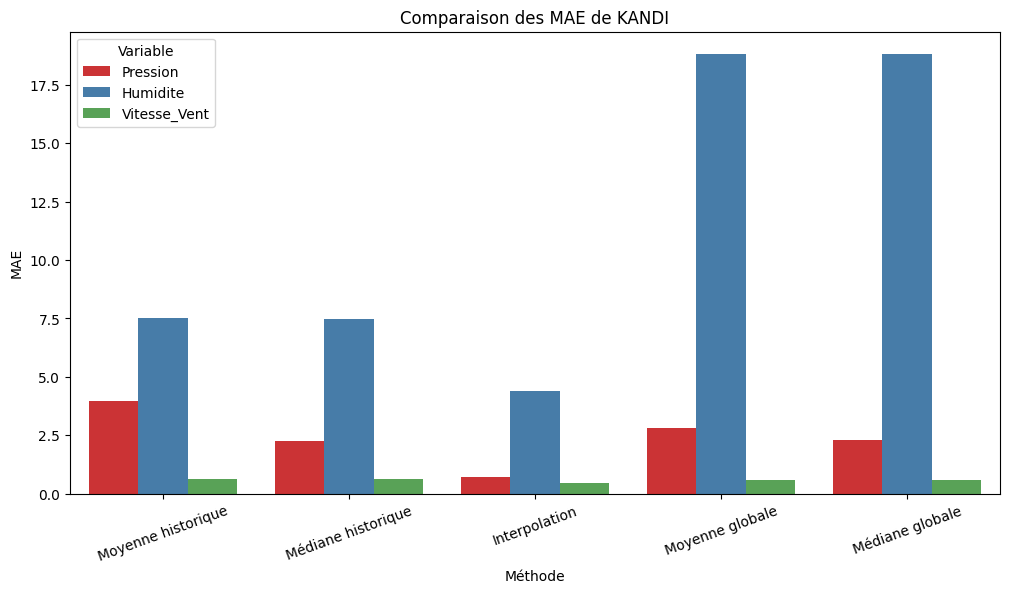

In [37]:
plt.figure(figsize=(12,6))
sns.barplot(data=df_resultat_Kandi,
    x="Méthode",
    y="MAE",
    hue="Variable",
    palette="Set1"
)

plt.title("Comparaison des MAE de KANDI")
plt.xticks(rotation=20)
plt.show()

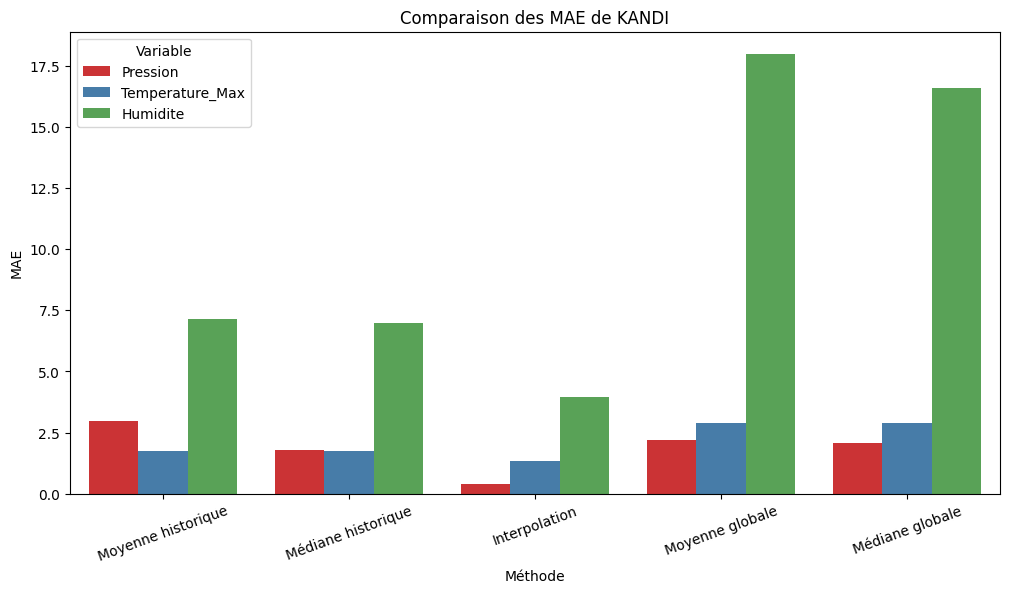

In [38]:
plt.figure(figsize=(12,6))
sns.barplot(data=df_resultat_Parakou,
    x="Méthode",
    y="MAE",
    hue="Variable",
    palette="Set1"
)

plt.title("Comparaison des MAE de KANDI")
plt.xticks(rotation=20)
plt.show()